In [ ]:
import os

import cmcrameri.cm as cmc
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from rich import print
from tqdm.notebook import tqdm

In [2]:
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print(f"Current Working Directory: {os.getcwd()}")

Current Working Directory: /Volumes/X31/01.Projects/atem

In [32]:
areas = ["NW", "NE", "tielines", "SW", "SE"]

dx = 50

In [ ]:
# Binning functions
from tools.tools import binning, binning_normal

In [35]:
results_gaussian = {}
results_normal = {}
for area in tqdm(areas):
    results_gaussian[area] = binning(dx, area)
    results_normal[area] = binning_normal(dx, area)

    picker = results_gaussian[area]["picker"]
    values = results_gaussian[area]["values"]
    results_gaussian[area]["values"] = pd.DataFrame(
        data = np.vstack(values),
        columns = ["Line", "distance"] + picker[1:]
    )
    picker = results_normal[area]["picker"]
    values = results_normal[area]["values"]
    results_normal[area]["values"] = pd.DataFrame(
        data = np.vstack(values),
        columns = ["Line", "distance"] + picker[1:]
    )

  0%|          | 0/5 [00:00<?, ?it/s]

In [36]:
print("Line Information:")
for area in areas:
    data = results_gaussian[area]["values"]
    line = data["Line"].unique()
    print(f"{area}: from {line[0]} to {line[-1]} with {len(line)} lines")

Line Information:

NW: from L10791 to L11982 with 118 lines

NE: from L10040 to L10795 with 136 lines

tielines: from T19010 to T29252 with 57 lines

SW: from L20610 to L21555 with 115 lines

SE: from L20010 to L20600 with 87 lines

In [37]:
print("EM data sampling interval average distance:")
for area in areas:
    data = results_gaussian[area]["values"]
    soundings = results_gaussian[area]["soundings"]
    offset = 0
    d = data["distance"]
    ddiff = np.zeros(len(soundings))
    ii = 0
    for i in soundings:
        next_offset = offset + i
        line_slice = slice(offset, next_offset)
        offset = next_offset
        ddiff[ii] = np.diff(d[line_slice]).sum()/i
        ii+=1

    print(f"{area}: {ddiff.mean()}")

EM data sampling interval average distance:

NW: 49.82663171578659

NE: 49.85050299021638

tielines: 49.87841644255852

SW: 49.8859568017848

SE: 49.895227111306816

Text(0.5, 0.98, 'Number of Soundings per Bin for Each Line')

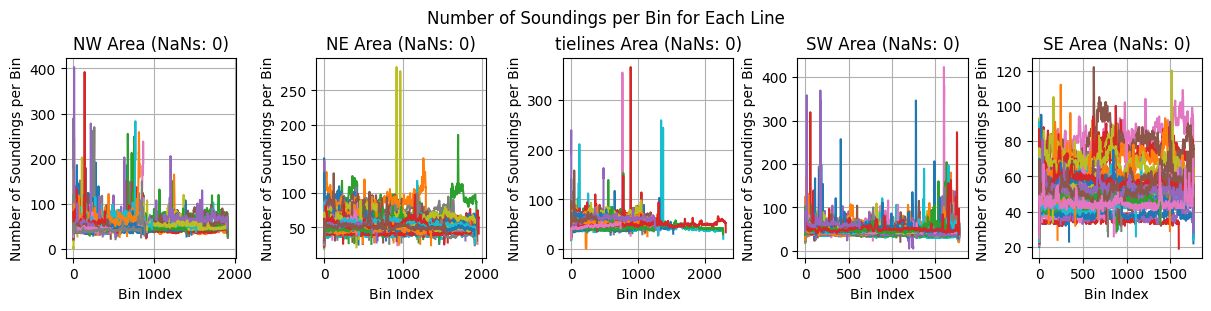

In [38]:
fig, axes = plt.subplot_mosaic([areas], figsize=(12, 3), constrained_layout=True)
for i, area in enumerate(areas):
    nlines = len(results_gaussian[area]["soundings"])
    tmp = results_gaussian[area]["values"] 
    nan_counts = np.isnan(
        tmp["x_wgs84"].values.astype(float)
    ).sum()
    for i in range(nlines):
        bin_counts = results_gaussian[area]["size"][i]
        axes[area].plot(bin_counts, label=f"{area} Line {i+1}")
    axes[area].set_ylabel("Number of Soundings per Bin")
    axes[area].set_xlabel("Bin Index")
    axes[area].grid()
    axes[area].set_title(f"{area} Area (NaNs: {nan_counts})")
plt.suptitle("Number of Soundings per Bin for Each Line")

Text(0.5, 0.98, 'Number of Soundings per Bin for Each Line')

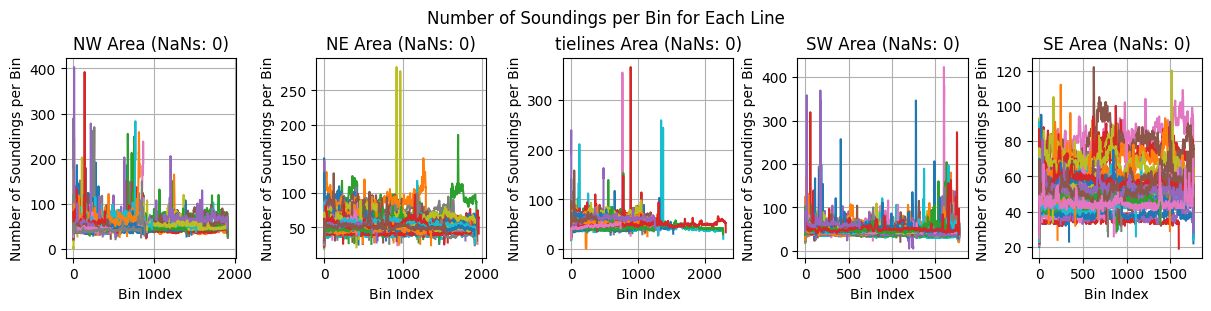

In [39]:
fig, axes = plt.subplot_mosaic([areas], figsize=(12, 3), constrained_layout=True)
for i, area in enumerate(areas):
    nlines = len(results_normal[area]["soundings"])
    tmp = results_normal[area]["values"] 
    nan_counts = np.isnan(
        tmp["x_wgs84"].values.astype(float)
    ).sum()
    for i in range(nlines):
        bin_counts = results_normal[area]["size"][i]
        axes[area].plot(bin_counts, label=f"{area} Line {i+1}")
    axes[area].set_ylabel("Number of Soundings per Bin")
    axes[area].set_xlabel("Bin Index")
    axes[area].grid()
    axes[area].set_title(f"{area} Area (NaNs: {nan_counts})")
plt.suptitle("Number of Soundings per Bin for Each Line")

In [40]:
def min_max_scaler(x):
    x = x.astype(float)
    log_x = np.log10(np.abs(x) + 1e-3)
    if log_x.max() - log_x.min() < 1e-3:
        scaled_x = np.zeros_like(log_x)
    else:
        scaled_x = (log_x - log_x.min()) / (log_x.max() - log_x.min())
    return scaled_x

Text(0.5, 0.98, 'Normalized Height Distribution')

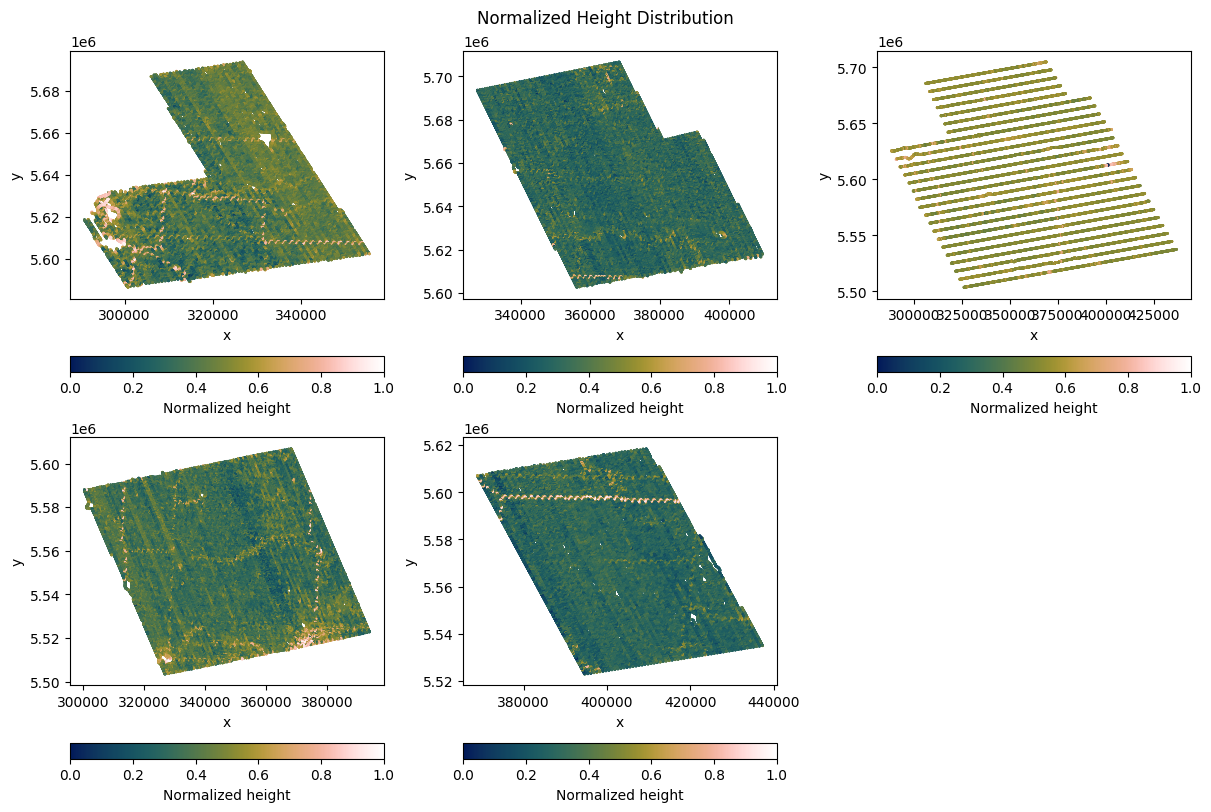

In [41]:
fig, axes = plt.subplot_mosaic(
    [areas[:3], areas[3:] + ["empty"]], figsize=(12, 8), constrained_layout=True
)
for i, area in enumerate(areas):
    nlines = len(results_normal[area]["soundings"])
    x = results_normal[area]["values"]["x_wgs84"]
    y = results_normal[area]["values"]["y_wgs84"]
    c = results_normal[area]["values"]["bheight"]
    scaled_c = min_max_scaler(c)
    a = axes[area].scatter(x, y, c=scaled_c, cmap=cmc.batlowW, s=1)
    axes[area].set_ylabel("y")
    axes[area].set_xlabel("x")
    plt.colorbar(a, ax=axes[area], label="Normalized height", orientation="horizontal")
axes["empty"].axis("off")
plt.suptitle("Normalized Height Distribution")

Text(0.5, 0.98, 'Normalized Power Line Distribution')

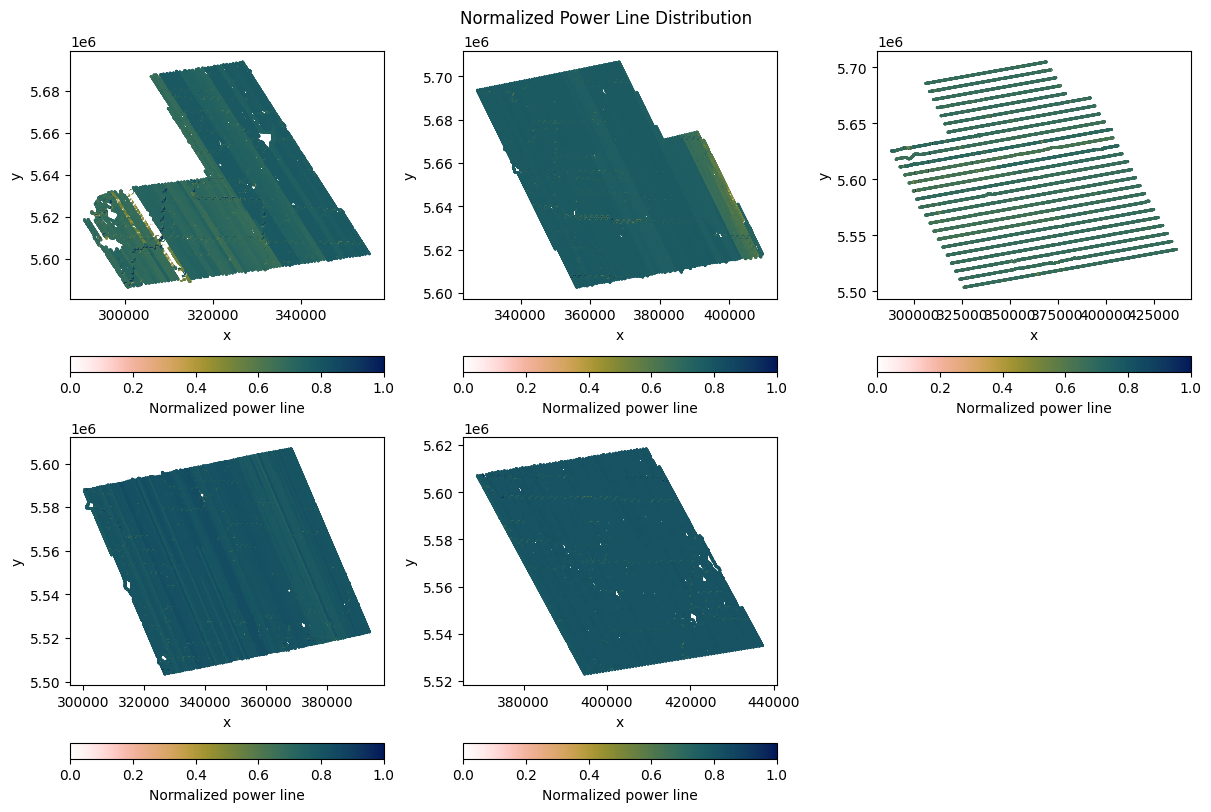

In [42]:
fig, axes = plt.subplot_mosaic(
    [areas[:3], areas[3:] + ["empty"]], figsize=(12, 8), constrained_layout=True
)
for i, area in enumerate(areas):
    nlines = len(results_normal[area]["soundings"])
    x = results_normal[area]["values"]["x_wgs84"]
    y = results_normal[area]["values"]["y_wgs84"]
    c = results_normal[area]["values"]["pwrline"]
    scaled_c = min_max_scaler(c)
    a = axes[area].scatter(x, y, c=scaled_c, cmap=cmc.batlowW_r, s=1)
    axes[area].set_ylabel("y")
    axes[area].set_xlabel("x")
    plt.colorbar(
        a, ax=axes[area], label="Normalized power line", orientation="horizontal"
    )
axes["empty"].axis("off")
plt.suptitle("Normalized Power Line Distribution")

Text(0.5, 0.98, 'Normalized DTM Distribution')

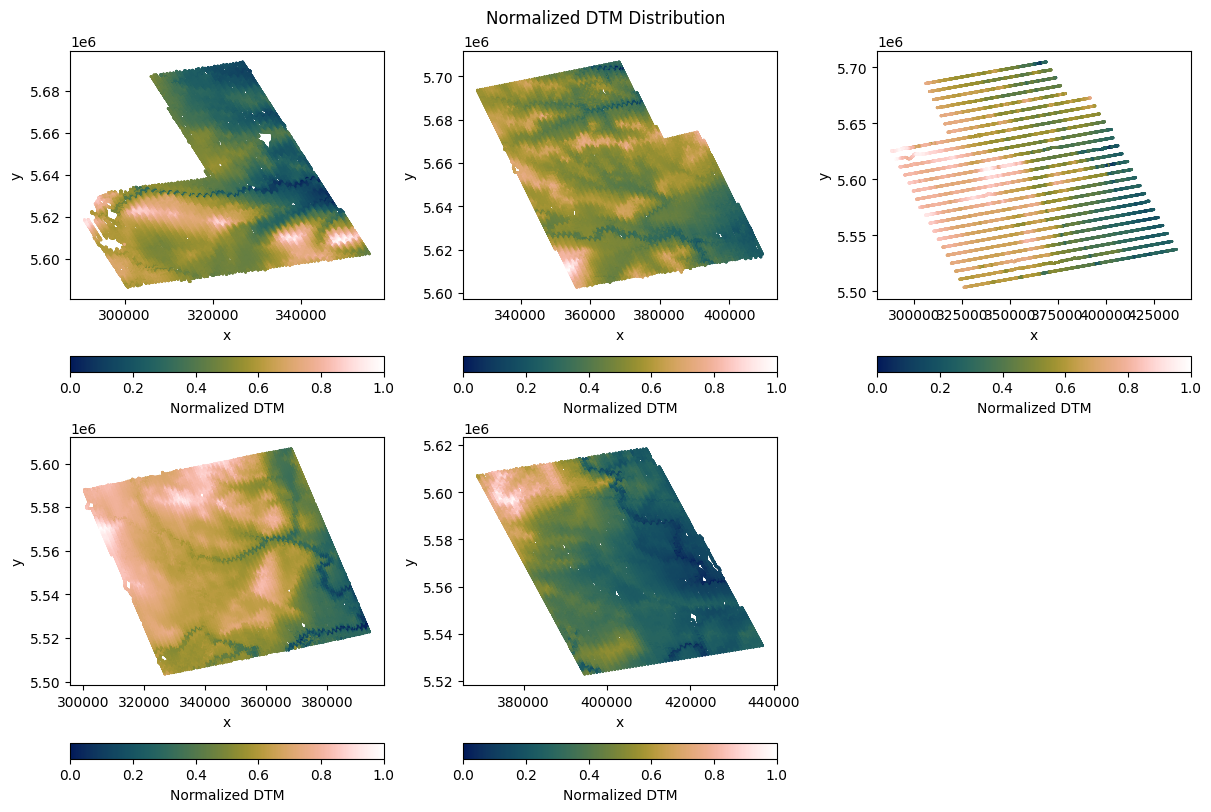

In [43]:
fig, axes = plt.subplot_mosaic(
    [areas[:3], areas[3:] + ["empty"]], figsize=(12, 8), constrained_layout=True
)
for i, area in enumerate(areas):
    nlines = len(results_normal[area]["soundings"])
    x = results_normal[area]["values"]["x_wgs84"]
    y = results_normal[area]["values"]["y_wgs84"]
    c = results_normal[area]["values"]["dtm"]
    scaled_c = min_max_scaler(c)
    a = axes[area].scatter(x, y, c=scaled_c, cmap=cmc.batlowW, s=1)
    axes[area].set_ylabel("y")
    axes[area].set_xlabel("x")
    plt.colorbar(
        a, ax=axes[area], label="Normalized DTM", orientation="horizontal"
    )
axes["empty"].axis("off")
plt.suptitle("Normalized DTM Distribution")